# 256 trend timing rules on SPY

**Author:** Franz Triebe · **Date:** 2026-10-11 · **Status:** final

**Question.** If we try 256 variants of classic trend timing rules on SPY (the 200 day moving average rule among them) and rank them by Sharpe ratio, what does the leaderboard look like, and how many genuinely different bets are hidden in those 256 trials? This notebook deliberately stops **before** the referee: the verdict comes in Phase 4.

**Data.** SPY daily adjusted closes from Yahoo Finance (dividends reinvested), retrieved 2026-10-11, and the daily one month T bill rate from the Ken French data library. Common sample after the longest warmup: April 1994 to October 2026.

> **Key findings**
> 1. The best of 256 trials, `x50_250_lf_vt_w`, shows a Sharpe ratio of **0.68** against **0.53** for buy and hold on the same dates (April 1994 to October 2026), with a maximum drawdown of 20% instead of 55%. The famous 200 day rule ranks 60th with 0.58.
> 2. Only **32%** of the trials beat buy and hold, and the top of the leaderboard is crowded: the best 15 trials all lie between 0.65 and 0.68, and all of them are slow, long/flat rules.
> 3. The 256 trials are far from 256 independent bets: their average correlation is **0.59**, and the effective number of trials is somewhere between **2.5** and **105**, depending on the approximation.

**Contents**
1. [Setup](#1.-Setup)
2. [Data](#2.-Data)
3. [Method](#3.-Method)
4. [Results](#4.-Results)
5. [Conclusions](#5.-Conclusions)
6. [Appendix A: all 256 trials](#6.-Appendix-A:-all-256-trials)
7. [Appendix B: environment](#7.-Appendix-B:-environment)

## 1. Setup

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import quantlab
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from quantlab import backtest, data, plotting, stats, strategies, validation

In [2]:
TICKER = "SPY"  # Yahoo symbol; adjusted closes make it a total return series
START = "1993-01-01"  # first date to load; trials start after their warmup
LAG = 1  # trading days between a decision at the close and the first return it earns
COST_BPS = 5.0  # cost per unit of one way turnover, in basis points
ANN_FACTOR = 252  # trading days per year
PROJECT = "p01"  # project name in the trial ledger
REFRESH = False  # True downloads fresh data instead of using the cache in data/
OUTPUT_DIR = Path(quantlab.__file__).resolve().parents[1] / "output" / "p01"

In [3]:
plotting.apply_style()
pd.options.display.float_format = "{:,.4f}".format
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PALETTE = plotting.PALETTE
SOURCE = (
    "Source: Yahoo Finance (SPY adjusted close), Ken French data library (T bill rate)."
)

## 2. Data

Same data as notebook 01. The trend rules need a price level, so we rebuild a **total return index** from the daily returns, $P_t = \prod_{s \le t} (1 + r_s)$. Moving average rules only compare prices with each other, so the starting level does not matter.

> **Assumption:** the risk free rate for the last few weeks, not yet published by Ken French, is carried forward (see notebook 01).

In [4]:
returns = data.load_yahoo(TICKER, start=START, refresh=REFRESH)
rf_published = data.load_rf_daily(refresh=REFRESH)
rf = rf_published.reindex(returns.index).ffill()
prices = (1 + returns).cumprod().rename("total return index")

assert (
    returns.index.is_monotonic_increasing
    and not returns.isna().any()
    and not rf.isna().any()
)
print(
    f"{len(returns):,} daily returns from {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}"
)

8,481 daily returns from 1993-02-01 to 2026-10-09


## 3. Method

### 3.1 The trial family

Every rule looks only at prices up to and including today's close and returns a **target weight**. The lag happens in one place only, `backtest.run`, so a weight set at Monday's close earns Tuesday's return.

| Family | Bullish when | Parameters | Signals |
| --- | --- | --- | --- |
| A: price above SMA | $P_t > \text{SMA}_L(t)$ | $L \in \{20, 50, 100, 150, 200, 250, 300\}$ | 7 |
| B: SMA crossover | $\text{SMA}_{fast}(t) > \text{SMA}_{slow}(t)$ | fast $\in \{5, 10, 20, 50\}$, slow $\in \{50, 100, 150, 200, 250\}$, fast below slow | 19 |
| C: time series momentum | $P_t / P_{t-21k} > 1$ | $k \in \{1, 2, 3, 6, 9, 12\}$ months | 6 |

Each of the 32 signals comes in $2 \times 2 \times 2 = 8$ variants, giving **256 trials**:

* **direction:** long/flat (`lf`: weight 1 when bullish, 0 otherwise) or long/short (`ls`: +1 or $-1$)
* **sizing:** full (`full`: $|w| = 1$) or volatility targeted (`vt`: $w \times \min(1, 15\% / \hat\sigma_t)$ with an EWMA volatility estimate, halflife 20 days)
* **rebalancing:** daily (`d`) or weekly (`w`: the weight set on the last trading day of a week is held through the next week)

Trial ids read like `sma200_lf_full_d` (price above its 200 day average, long/flat, full size, daily) or `x50_250_lf_vt_w` (50 day average above the 250 day average, long/flat, volatility targeted, weekly). Buy and hold is the **benchmark**, not a trial.

In [5]:
trials = strategies.build_trials(prices)
results = backtest.run_all(trials, returns, lag=LAG, cost_bps=COST_BPS, rf=rf)
sample = next(iter(results.values())).index
common_start = max(w.first_valid_index() for w in trials.values())
benchmark = backtest.run(
    pd.Series(1.0, index=returns.index).where(returns.index >= common_start),
    returns,
    lag=LAG,
    cost_bps=COST_BPS,
    rf=rf,
).loc[sample]

assert len(trials) == 256 and all(r.index.equals(sample) for r in results.values())
assert not benchmark.isna().any().any()
print(
    f"Common sample: {sample[0]:%Y-%m-%d} to {sample[-1]:%Y-%m-%d}, {len(sample):,} days ({len(sample) / ANN_FACTOR:.1f} years)"
)

Common sample: 1994-04-11 to 2026-10-09, 8,180 days (32.5 years)


### 3.2 One rule up close: the 200 day moving average in the financial crisis

The classic rule `sma200_lf_full_d` holds SPY while it trades above its 200 day average and sits in cash otherwise. The shaded areas are the days it was invested.

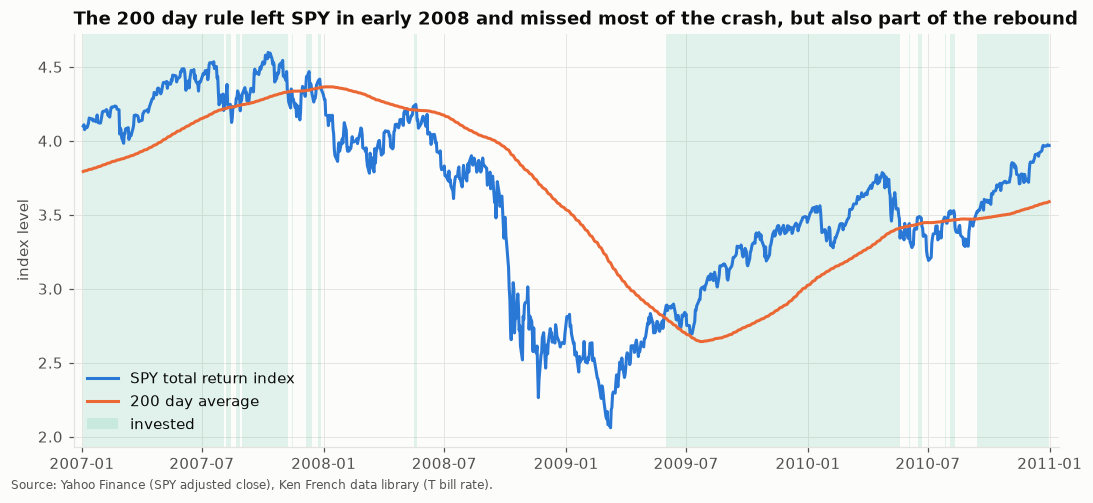

In [6]:
window = slice("2007-01-01", "2010-12-31")
sma200 = strategies.sma(prices, 200).loc[window]
held = results["sma200_lf_full_d"]["position"].loc[window]
fig, ax = plt.subplots()
ax.plot(prices.loc[window], color=PALETTE["primary"], label="SPY total return index")
ax.plot(sma200, color=PALETTE["comparison"], label="200 day average")
ax.fill_between(
    held.index,
    0,
    1,
    where=held > 0,
    transform=ax.get_xaxis_transform(),
    color=PALETTE["third"],
    alpha=0.12,
    linewidth=0,
    label="invested",
)
ax.set_ylabel("index level")
ax.set_title(
    "The 200 day rule left SPY in early 2008 and missed most of the crash, but also part of the rebound"
)
ax.legend(loc="lower left")
ax.margins(x=0.01)
fig.text(0.01, 0, SOURCE, fontsize=8, alpha=0.7)
fig.tight_layout()
plt.show()

**Reading the chart.** In the second half of 2007 the rule switched in and out nine times as SPY hovered around its average; each switch costs trading costs. It left for good on 31 December 2007, apart from a brief return in May 2008, and so sat out the 55% fall to the March 2009 low. It only came back on 1 June 2009, when SPY was already 40% above that low. That is the trade of every trend rule: it gives up the start of each rebound and pays for whipsaws in exchange for avoiding most of each long decline.

## 4. Results

### 4.1 The leaderboard

Summary statistics for every trial, sorted by Sharpe ratio. The table shows the top 15 and the bottom 5, with buy and hold on the same dates for comparison; Appendix A lists all 256.

In [7]:
summary = pd.DataFrame(
    {
        k: stats.summary(r["excess"], total=r["total"], position=r["position"])
        for k, r in results.items()
    }
).T
summary = summary.sort_values("sharpe", ascending=False)
summary.insert(0, "rank", np.arange(1, len(summary) + 1))
bench_summary = stats.summary(
    benchmark["excess"], total=benchmark["total"], position=benchmark["position"]
)

COLUMNS = [
    "rank",
    "sharpe",
    "ann_mean_excess",
    "ann_vol",
    "max_drawdown",
    "time_in_market",
    "turnover_per_year",
]
FORMATS = {
    "rank": "{:.0f}",
    "sharpe": "{:.2f}",
    "ann_mean_excess": "{:.1%}",
    "ann_vol": "{:.1%}",
    "max_drawdown": "{:.1%}",
    "time_in_market": "{:.0%}",
    "turnover_per_year": "{:.1f}",
}
leaderboard = pd.concat(
    [
        summary.head(15),
        bench_summary.to_frame("buy and hold (benchmark)").T,
        summary.tail(5),
    ]
)[COLUMNS]
display(leaderboard.style.format(FORMATS, na_rep=""))

,rank,sharpe,ann_mean_excess,ann_vol,max_drawdown,time_in_market,turnover_per_year
x50_250_lf_vt_w,1,0.68,8.0%,11.7%,-20.2%,78%,1.1
x50_250_lf_vt_d,2,0.68,7.9%,11.6%,-20.0%,78%,1.5
sma300_lf_vt_d,3,0.68,7.7%,11.3%,-17.4%,80%,3.1
x10_200_lf_full_d,4,0.68,8.4%,12.5%,-20.2%,77%,1.8
sma300_lf_full_d,5,0.67,8.7%,12.9%,-23.0%,80%,3.1
sma300_lf_vt_w,6,0.67,7.7%,11.5%,-19.9%,80%,1.7
tsm9_lf_full_w,7,0.67,8.9%,13.4%,-26.7%,80%,2.2
tsm9_lf_vt_w,8,0.66,7.6%,11.5%,-19.9%,80%,2.3
x10_200_lf_vt_d,9,0.66,7.3%,11.1%,-18.4%,77%,2.3
x50_200_lf_vt_d,10,0.66,7.6%,11.5%,-19.3%,77%,1.6


**Reading the table.** All of the top 15 are long/flat and slow: 250 and 300 day averages, 200 and 250 day crossovers, 9 month momentum. They earn less than buy and hold per year (about 8% above cash instead of 9.9%) but with far less volatility (about 12% instead of 19%) and drawdowns of 17% to 34% instead of 55%, which is where their higher Sharpe ratio comes from. The differences between them are tiny, 0.65 to 0.68, so their order is mostly noise. At the bottom are fast long/short rules (20 and 50 day averages, 1 month momentum) that trade 35 to 59 times a year and lost 67% to 89% at their worst.

### 4.2 The distribution of all 256 Sharpe ratios

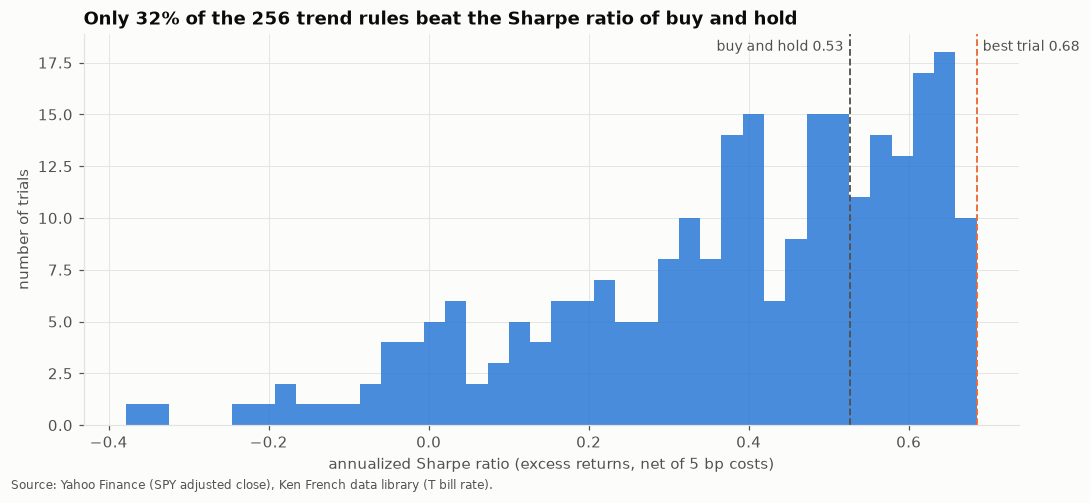

In [8]:
share_beating = (summary["sharpe"] > bench_summary["sharpe"]).mean()
winner = summary.index[0]
fig, ax = plt.subplots()
ax.hist(summary["sharpe"], bins=40, color=PALETTE["primary"], alpha=0.85)
plotting.reference_line(
    ax,
    bench_summary["sharpe"],
    f"buy and hold {bench_summary['sharpe']:.2f}",
    axis="x",
    side="left",
)
plotting.reference_line(
    ax,
    summary["sharpe"].iloc[0],
    f"best trial {summary['sharpe'].iloc[0]:.2f}",
    axis="x",
    color=PALETTE["comparison"],
)
ax.set_xlabel("annualized Sharpe ratio (excess returns, net of 5 bp costs)")
ax.set_ylabel("number of trials")
ax.set_title(
    f"Only {share_beating:.0%} of the 256 trend rules beat the Sharpe ratio of buy and hold"
)
fig.text(0.01, 0, SOURCE, fontsize=8, alpha=0.7)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "trial_sharpes.png")
plt.show()

**Reading the chart.** The median trial has a Sharpe ratio of 0.42, below buy and hold. The long left tail is the fast long/short rules. The best trial sits at the very right edge, and it is this single number that a naive researcher would report.

### 4.3 Which design choices matter?

Average and best Sharpe ratio for each value of the four design dimensions.

In [9]:
parts = summary.index.to_series().str.rsplit("_", n=3, expand=True)
parts.columns = ["signal", "direction", "sizing", "rebalancing"]
parts["family"] = (
    parts["signal"]
    .str.extract(r"^(sma|x|tsm)")[0]
    .map({"sma": "A: price above SMA", "x": "B: SMA crossover", "tsm": "C: momentum"})
)
choices = pd.concat(
    {
        dim: summary.groupby(parts[dim])["sharpe"].agg(["mean", "max", "count"])
        for dim in ["family", "direction", "sizing", "rebalancing"]
    }
)
choices.index.names = ["dimension", "value"]
display(choices.style.format({"mean": "{:.2f}", "max": "{:.2f}", "count": "{:.0f}"}))

**Reading the table.** Direction matters most: long/flat trials average 0.53 and long/short trials 0.23. Shorting an index that rose about 10% a year above cash mostly costs money. Volatility targeting helps on average (0.41 against 0.35), because it cuts exposure exactly when markets are turbulent, which is also when trend rules whipsaw. Weekly rebalancing is slightly better than daily (0.39 against 0.37), since it trades less. The crossover family has the highest average, but every family has a member near the top.

### 4.4 How many independent bets are 256 trials?

Trend rules on the same index are close relatives (Levine and Pedersen 2016): they are long in the same bull markets and out in the same crashes. The correlation matrix of the 256 daily trial returns shows how close.

In [10]:
excess = backtest.run_many(trials, returns, lag=LAG, cost_bps=COST_BPS, rf=rf)
corr = excess.corr()
off_diagonal = corr.to_numpy()[np.triu_indices(len(corr), k=1)]
eigenvalues = np.linalg.eigvalsh(corr.to_numpy())[::-1]
n_eff = {
    "average correlation": validation.n_eff_avgcorr(excess),
    "eigenvalues": validation.n_eff_eigen(excess),
}
print(
    f"Average pairwise correlation {off_diagonal.mean():.2f} (from {off_diagonal.min():.2f} to {off_diagonal.max():.2f})"
)
print(
    f"The first principal component explains {eigenvalues[0] / eigenvalues.sum():.0%} of the total variance"
)
for method, value in n_eff.items():
    print(f"Effective number of trials, {method}: {value:.1f}")

Average pairwise correlation 0.59 (from -0.19 to 1.00)
The first principal component explains 62% of the total variance
Effective number of trials, average correlation: 104.9
Effective number of trials, eigenvalues: 2.5


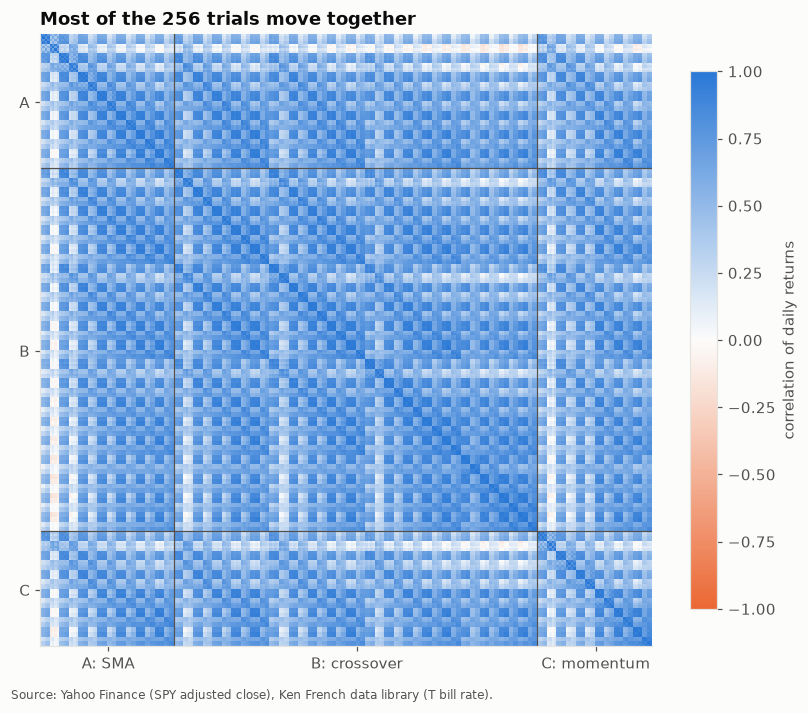

In [11]:
cmap = LinearSegmentedColormap.from_list(
    "house", [PALETTE["comparison"], PALETTE["surface"], PALETTE["primary"]]
)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
image = ax.imshow(
    corr.loc[list(trials), list(trials)],
    cmap=cmap,
    vmin=-1,
    vmax=1,
    interpolation="nearest",
)
edges = [0, 56, 208, 256]
ax.set_xticks(
    [(a + b) / 2 for a, b in zip(edges[:-1], edges[1:], strict=True)],
    ["A: SMA", "B: crossover", "C: momentum"],
)
ax.set_yticks(
    [(a + b) / 2 for a, b in zip(edges[:-1], edges[1:], strict=True)], ["A", "B", "C"]
)
for edge in edges[1:-1]:
    ax.axhline(edge - 0.5, color=PALETTE["text_secondary"], linewidth=0.8)
    ax.axvline(edge - 0.5, color=PALETTE["text_secondary"], linewidth=0.8)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="correlation of daily returns")
ax.set_title("Most of the 256 trials move together")
fig.text(0.01, 0, SOURCE, fontsize=8, alpha=0.7)
fig.tight_layout()
plt.show()

**Reading the chart.** Almost the whole matrix is blue: most pairs of trials have correlations between 0.3 and 1.0, and only a few long/short pairs are slightly negative. The checkerboard pattern comes from the long/flat and long/short versions of each signal alternating in the ordering.

The two estimates of the effective number of trials disagree strongly, and both are simple approximations:

* **Average correlation (105):** $\bar\rho + (1-\bar\rho)N$ interpolates linearly between 1 (all identical) and N (all independent). With $\bar\rho = 0.59$ it keeps 41% of the 256 trials.
* **Eigenvalues (2.5):** $(\sum\lambda_i)^2 / \sum\lambda_i^2$ is dominated by the first principal component, which alone explains 62% of the variance (the common "in the market or not" factor). It says the family behaves like two or three bets.

The truth lies somewhere in between. Phase 4 reports the deflated Sharpe ratio for all three counts (256, 105 and 2.5), so we can see how much the verdict depends on this choice.

### 4.5 Saving the trials and counting them in the ledger

Every backtest variant is a trial, so all 256 go into the permanent trial ledger now. Phase 4 reads the count from there.

In [12]:
data_id = f"{TICKER} {sample[0]:%Y-%m-%d} {sample[-1]:%Y-%m-%d}"
summary.to_csv(OUTPUT_DIR / "trials.csv")
validation.ledger_append(PROJECT, data_id, summary)
print(
    f"Ledger now counts {validation.ledger_count(PROJECT, data_id)} distinct trials for {data_id}"
)

Ledger now counts 256 distinct trials for SPY 1994-04-11 2026-10-09


## 5. Conclusions

1. **The leaderboard looks attractive.** The best trial beats buy and hold with a Sharpe ratio of 0.68 against 0.53 over 32.5 years and cuts the worst drawdown from 55% to 20%.
2. **But it is a crowded race.** Only 32% of the trials beat buy and hold, the best 15 are separated by 0.03 in Sharpe ratio, and the winner was chosen with hindsight from 256 tries.
3. **256 trials are not 256 bets.** With an average correlation of 0.59, the family is worth somewhere between 2.5 and 105 independent trials. How many we count decides how high the hurdle is in Phase 4.

> **Caveats:** the family contains famous rules (the 200 day average, 12 month momentum) that became famous partly because they worked in the past, so even 256 is an undercount of the true search. Results are for one index and one period.

### Your turn, before Phase 4

Write down your answers now, before the referee speaks (PLAN.md: "Franz writes down which result he would believe and why"):

1. Which trial would you put money on, and why that one?
2. What Sharpe ratio do you expect it to earn over the next ten years: closer to 0.68, to 0.53 (buy and hold), or lower?
3. What evidence would change your mind?

## 6. Appendix A: all 256 trials

Sorted by Sharpe ratio, same columns as Section 4.1.

In [13]:
display(summary[COLUMNS].style.format(FORMATS))

,rank,sharpe,ann_mean_excess,ann_vol,max_drawdown,time_in_market,turnover_per_year
x50_250_lf_vt_w,1,0.68,8.0%,11.7%,-20.2%,78%,1.1
x50_250_lf_vt_d,2,0.68,7.9%,11.6%,-20.0%,78%,1.5
sma300_lf_vt_d,3,0.68,7.7%,11.3%,-17.4%,80%,3.1
x10_200_lf_full_d,4,0.68,8.4%,12.5%,-20.2%,77%,1.8
sma300_lf_full_d,5,0.67,8.7%,12.9%,-23.0%,80%,3.1
sma300_lf_vt_w,6,0.67,7.7%,11.5%,-19.9%,80%,1.7
tsm9_lf_full_w,7,0.67,8.9%,13.4%,-26.7%,80%,2.2
tsm9_lf_vt_w,8,0.66,7.6%,11.5%,-19.9%,80%,2.3
x10_200_lf_vt_d,9,0.66,7.3%,11.1%,-18.4%,77%,2.3
x50_200_lf_vt_d,10,0.66,7.6%,11.5%,-19.3%,77%,1.6


## 7. Appendix B: environment

In [14]:
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "quantlab": version("quantlab"),
}
print(", ".join(f"{k} {v}" for k, v in versions.items()))

python 3.12.11, numpy 2.5.4, pandas 3.0.6, matplotlib 3.11.2, quantlab 0.1.0
